## Clasificador Bayesiano Ingenuo para dígitos manuscritos (`sklearn.datasets.load_digits`)

Integrantes: Juan Diego Palacios Pacheco & Andrea de la Ossa

## 1. Librerías y configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB, CategoricalNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=UserWarning)

## 2. Los datos

`load_digits` contiene **1797 imágenes de 8×8 píxeles** (64 atributos) de dígitos manuscritos. Cada píxel es un **entero entre 0 y 16** que indica la intensidad de "tinta" (0 = blanco, 16 = trazo máximo). Hay 10 clases (0–9) aproximadamente balanceadas.

Forma de X: (1797, 64) | Forma de y: (1797,)
Tipo de dato: float64 | ¿Todos enteros?: True
Valores distintos de los píxeles: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
Mínimo / máximo: 0.0 / 16.0
Proporción de píxeles iguales a 0: 48.9 %

Ejemplos por clase:
 0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180


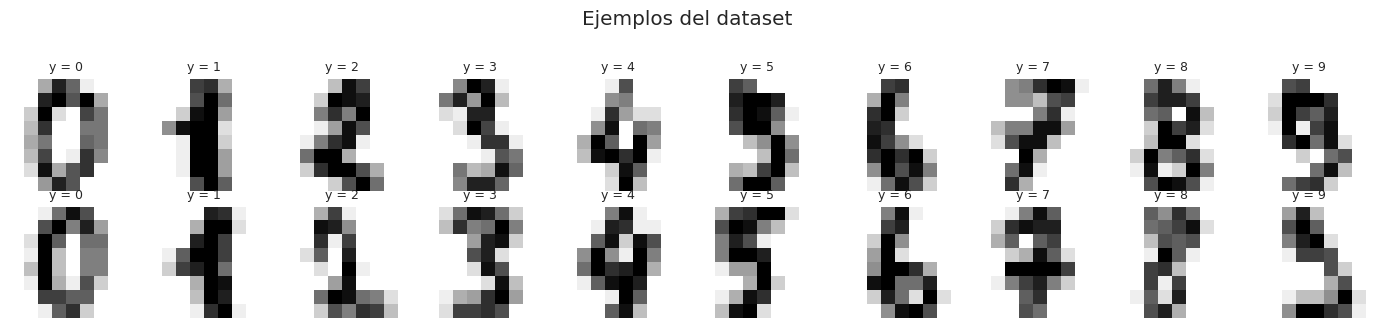

In [2]:
digits = load_digits()
X, y = digits.data, digits.target

print("Forma de X:", X.shape, "| Forma de y:", y.shape)
print("Tipo de dato:", X.dtype, "| ¿Todos enteros?:", np.all(X == X.astype(int)))
print("Valores distintos de los píxeles:", np.unique(X).astype(int))
print("Mínimo / máximo:", X.min(), "/", X.max())
print("Proporción de píxeles iguales a 0: %.1f %%" % (100 * (X == 0).mean()))
print("\nEjemplos por clase:\n", pd.Series(y).value_counts().sort_index().to_string())

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for ax, img, lab in zip(axes.ravel(), digits.images[:20], y[:20]):
    ax.imshow(img, cmap="gray_r"); ax.set_title(f"y = {lab}", fontsize=9); ax.axis("off")
plt.suptitle("Ejemplos del dataset", y=1.02); plt.tight_layout(); plt.show()

## 3. Partición 80 / 20 y validación cruzada (K = 4)

* **80 % entrenamiento / 20 % prueba**, de forma **estratificada** (conserva la proporción de cada dígito en ambos conjuntos).
* Toda la selección de modelo y de hiperparámetros se hace **solo con el 80 % de entrenamiento**, usando `StratifiedKFold(n_splits=4)`.
* El 20 % de prueba se usa **una única vez, al final**, para reportar el desempeño del modelo elegido. Así se evita filtrar información de prueba a las decisiones de diseño.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)

print(f"Entrenamiento: {X_train.shape[0]} muestras ({X_train.shape[0]/len(X):.0%})")
print(f"Prueba:        {X_test.shape[0]} muestras ({X_test.shape[0]/len(X):.0%})")
for i, (tr, va) in enumerate(cv.split(X_train, y_train), 1):
    print(f"  Fold {i}: {len(tr)} para ajustar / {len(va)} para validar")

SCORING = {"accuracy": "accuracy",
           "precision": "precision_macro",
           "recall": "recall_macro",
           "f1": "f1_macro"}

def cv_metrics(model, Xa=None, ya=None):
    # Promedio de las 4 particiones de las métricas (promedio macro entre clases)
    Xa = X_train if Xa is None else Xa
    ya = y_train if ya is None else ya
    r = cross_validate(model, Xa, ya, cv=cv, scoring=SCORING)
    out = {k: r[f"test_{k}"].mean() for k in SCORING}
    out["accuracy_std"] = r["test_accuracy"].std()
    return out

Entrenamiento: 1437 muestras (80%)
Prueba:        360 muestras (20%)
  Fold 1: 1077 para ajustar / 360 para validar
  Fold 2: 1078 para ajustar / 359 para validar
  Fold 3: 1078 para ajustar / 359 para validar
  Fold 4: 1078 para ajustar / 359 para validar


## 4. ¿Qué distribución siguen los datos?

Según el material de clase, el tipo de clasificador depende de la naturaleza de los atributos. Se examinan entonces los píxeles para decidir qué familia de distribuciones es razonable. Se analiza solo el conjunto de entrenamiento.

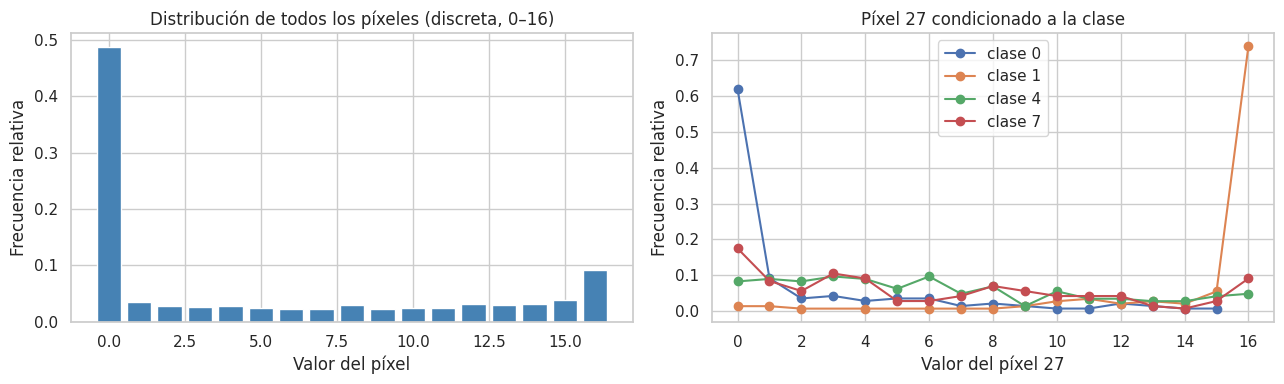

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# (a) Histograma global de los valores de los píxeles
vals, counts = np.unique(X_train, return_counts=True)
ax[0].bar(vals, counts / counts.sum(), color="steelblue")
ax[0].set_xlabel("Valor del píxel"); ax[0].set_ylabel("Frecuencia relativa")
ax[0].set_title("Distribución de todos los píxeles (discreta, 0–16)")

# (b) Histograma de un píxel central para varias clases
j = 27  # píxel (fila 3, col 3)
for c in [0, 1, 4, 7]:
    v, n = np.unique(X_train[y_train == c, j], return_counts=True)
    ax[1].plot(v, n / n.sum(), marker="o", label=f"clase {c}")
ax[1].set_xlabel(f"Valor del píxel {j}"); ax[1].set_ylabel("Frecuencia relativa")
ax[1].set_title(f"Píxel {j} condicionado a la clase"); ax[1].legend()
plt.tight_layout(); plt.show()

In [5]:
# ¿Se cumple la hipótesis Gaussiana? Prueba de normalidad de D'Agostino-Pearson por (clase, píxel)
rechazos, probados = 0, 0
for c in range(10):
    Xc = X_train[y_train == c]
    for j in range(64):
        if Xc[:, j].std() > 0:                 # se omiten píxeles constantes (no hay distribución que probar)
            probados += 1
            if stats.normaltest(Xc[:, j]).pvalue < 0.05:
                rechazos += 1

n_const = int(((X_train.std(axis=0)) == 0).sum())
print(f"Píxeles constantes en todo el entrenamiento: {n_const}")
print(f"Pares (clase, píxel) probados: {probados}")
print(f"Pares donde se RECHAZA normalidad (p < 0.05): {rechazos} ({rechazos/probados:.1%})")

# Fracción de ceros por clase y píxel: los píxeles son muy 'dispersos'
frac0 = np.mean([(X_train[y_train == c] == 0).mean() for c in range(10)])
print(f"Fracción media de ceros dentro de cada clase: {frac0:.1%}")

Píxeles constantes en todo el entrenamiento: 3
Pares (clase, píxel) probados: 511
Pares donde se RECHAZA normalidad (p < 0.05): 501 (98.0%)
Fracción media de ceros dentro de cada clase: 48.8%


**Lectura de los resultados**

* Los atributos son **enteros no negativos en {0, …, 16}**, no valores reales continuos.
* Cerca de la mitad de los píxeles vale exactamente 0 (hay un pico enorme en 0), y las distribuciones por clase son asimétricas y acotadas; la prueba de normalidad **rechaza la hipótesis Gaussiana** en la gran mayoría de los pares (clase, píxel). Un píxel de borde que casi siempre es 0 no se parece a una campana.
* Cada imagen puede verse como una "bolsa de píxeles": el valor de cada píxel es *cuánta tinta* cae en esa posición, análogo a la frecuencia de una palabra en un documento (el ejemplo de texto de las diapositivas de Multinomial). Es decir, un vector de **conteos/intensidades discretas no negativas**, con un número fijo de atributos para todas las muestras.

Esto apunta a una distribución **Multinomial** (conteos discretos no negativos) y no a una Gaussiana ni a una Bernoulli. Lo verificamos con datos a continuación.

## 5. Comparación de los tipos de clasificador (K-fold = 4)

Se comparan los cinco tipos vistos en clase sobre el conjunto de entrenamiento:

| Modelo | Supone | Ajuste a `digits` |
|---|---|---|
| `GaussianNB` | atributos continuos ~ Normal por clase | Datos discretos, con muchos ceros → ajuste pobre |
| `BernoulliNB` | atributos binarios (presente/ausente) | Hay que binarizar y se pierde la intensidad |
| `MultinomialNB` | conteos enteros ≥ 0 | Ajuste natural |
| `ComplementNB` | conteos, **clases desbalanceadas** | Aquí las clases están balanceadas → sin ventaja esperada |
| `CategoricalNB` | categorías nominales sin orden | Ignora que 15 está "más cerca" de 16 que de 2 |

Para `BernoulliNB` se prueban dos umbrales de binarización (`> 0` y `> 8`). Para `CategoricalNB` se fija `min_categories=17` para que reconozca los 17 niveles posibles aunque un fold no los vea todos.

,Exactitud,Precisión,Exhaustividad (recall),F1,Desv. exactitud
CategoricalNB,0.9068,0.9091,0.9064,0.9061,0.0170
MultinomialNB,0.9047,0.9121,0.9048,0.9050,0.0114
BernoulliNB (umbral > 8),0.8845,0.8904,0.8845,0.8851,0.0126
BernoulliNB (umbral > 0),0.8546,0.8597,0.8546,0.8535,0.0052
GaussianNB,0.8232,0.8652,0.8233,0.8240,0.0050
ComplementNB,0.8170,0.8411,0.8153,0.8007,0.0101


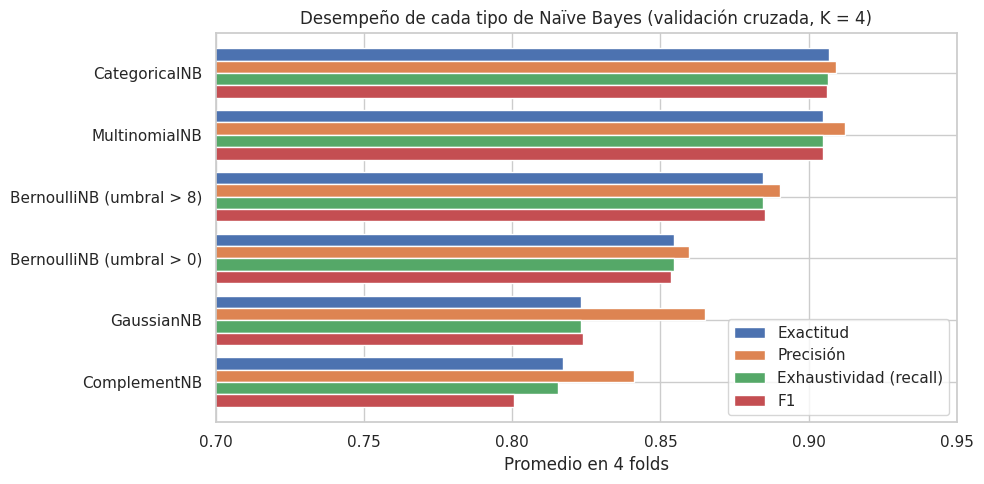

In [6]:
candidatos = {
    "GaussianNB":                GaussianNB(),
    "BernoulliNB (umbral > 0)":  BernoulliNB(binarize=0),
    "BernoulliNB (umbral > 8)":  BernoulliNB(binarize=8),
    "MultinomialNB":             MultinomialNB(),
    "ComplementNB":              ComplementNB(),
    "CategoricalNB":             CategoricalNB(min_categories=17),
}

filas = {nombre: cv_metrics(m) for nombre, m in candidatos.items()}
tabla = pd.DataFrame(filas).T.sort_values("f1", ascending=False)
tabla.columns = ["Exactitud", "Precisión", "Exhaustividad (recall)", "F1", "Desv. exactitud"]
display(tabla.round(4))

ax = tabla[["Exactitud", "Precisión", "Exhaustividad (recall)", "F1"]].plot.barh(figsize=(10, 5), width=0.8)
ax.set_xlim(0.7, 0.95); ax.invert_yaxis(); ax.set_xlabel("Promedio en 4 folds")
ax.set_title("Desempeño de cada tipo de Naïve Bayes (validación cruzada, K = 4)")
plt.tight_layout(); plt.show()

## 6. Elección del clasificador y justificación

**Elegido: `MultinomialNB`.**

Razones:

1. **Naturaleza de los datos.** Los 64 atributos son enteros no negativos (intensidades 0–16) con el mismo conjunto de atributos para todas las imágenes: exactamente el escenario descrito en clase para el modelo Multinomial. La verosimilitud es $P(\mathbf x\mid c)\propto\prod_j \theta_{cj}^{x_j}$, donde $\theta_{cj}$ es la fracción de la "tinta total" de la clase $c$ que cae en el píxel $j$.
2. **Evidencia empírica.** En validación cruzada es de los mejores modelos y claramente superior al Gaussiano, al Bernoulli y al Complementario. `CategoricalNB` queda prácticamente empatado (la diferencia está dentro de la desviación entre folds), pero lo descarto por parsimonia y por robustez: trata cada nivel de gris como una etiqueta *nominal* sin orden (aprende hasta 64 × 17 probabilidades por clase con ~140 imágenes por clase, así que muchas celdas quedan vacías) y, como se verá, es mucho más sensible a α. Multinomial estima solo 64 parámetros por clase.
3. **Por qué fallan los otros.** *Gaussiano*: la distribución es discreta, acotada y con un pico en 0, no normal (la prueba lo rechaza). *Bernoulli*: binarizar descarta la intensidad del trazo. *Complementario*: su ventaja es con clases desbalanceadas, y `digits` está balanceado.

**Distribución de los datos:** condicionalmente a la clase, la intensidad de cada píxel se modela como **Multinomial** (conteos discretos no negativos), con independencia condicional entre píxeles (supuesto "ingenuo", que en imágenes es claramente falso —píxeles vecinos están correlacionados—, pero aun así el clasificador funciona razonablemente).

## 7. Implementación desde cero del Multinomial con Suavizado de Laplace

Para entender el mecanismo se implementa el clasificador siguiendo exactamente la fórmula de las diapositivas. Para la clase $c$ y el píxel $j$:

$$
\theta_{cj}=\frac{N_{cj}+\alpha}{N_c+\alpha\, n}, \qquad N_{cj}=\sum_{i:\,y_i=c} x_{ij},\quad N_c=\sum_j N_{cj},\quad n=64
$$

Con $\alpha=0$ no hay suavizado. Para cada clase, $\sum_j\theta_{cj}=1$. La decisión es $\hat y=\arg\max_c\,[\log P(c)+\sum_j x_j\log\theta_{cj}]$.

In [7]:
class MultinomialNBManual:
    # Naïve Bayes Multinomial con suavizado de Laplace (alpha), implementado con NumPy.
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        n_feat = X.shape[1]
        self.class_log_prior_ = np.log(np.array([(y == c).mean() for c in self.classes_]))
        N_cj = np.array([X[y == c].sum(axis=0) for c in self.classes_])      # conteos por clase y píxel
        self.N_cj_ = N_cj
        # (N_cj + alpha) / (N_c + alpha * n)
        self.theta_ = (N_cj + self.alpha) / (N_cj.sum(axis=1, keepdims=True) + self.alpha * n_feat)
        return self

    def joint_log_likelihood(self, X):
        with np.errstate(divide="ignore", invalid="ignore"):
            log_theta = np.log(self.theta_)                                   # puede contener -inf si alpha = 0
            # convención 0 * log(0) = 0: solo cuentan los píxeles con tinta (x > 0)
            ll = np.where(X[:, None, :] > 0, X[:, None, :] * log_theta[None, :, :], 0.0).sum(axis=2)
        return ll + self.class_log_prior_

    def predict(self, X):
        return self.classes_[np.argmax(self.joint_log_likelihood(X), axis=1)]

# Verificación contra scikit-learn (alpha = 1)
manual = MultinomialNBManual(alpha=1.0).fit(X_train, y_train)
sk = MultinomialNB(alpha=1.0).fit(X_train, y_train)

print("¿Mismas predicciones que scikit-learn en prueba?:", np.array_equal(manual.predict(X_test), sk.predict(X_test)))
print("¿Mismos log P(x_j|c)?:", np.allclose(np.log(manual.theta_), sk.feature_log_prob_))
print("Cada fila de theta suma 1:", np.allclose(manual.theta_.sum(axis=1), 1.0))

¿Mismas predicciones que scikit-learn en prueba?: True
¿Mismos log P(x_j|c)?: True
Cada fila de theta suma 1: True


## 8. Efecto de α (suavizado de Laplace) sobre el desempeño

### 8.1. ¿Para qué sirve? El problema de las probabilidades cero
Si un píxel nunca tuvo tinta en las imágenes de entrenamiento de una clase, entonces $N_{cj}=0$ y, sin suavizado, $\theta_{cj}=0$. Basta que una imagen nueva tenga tinta en ese píxel para que $\log\theta_{cj}=-\infty$ y **esa clase quede descartada para siempre**, sin importar la evidencia de los otros 63 píxeles. Veamos cuántas veces ocurre.

In [8]:
ceros = (manual.N_cj_ == 0)
print(f"Pares (clase, píxel) sin ninguna tinta en entrenamiento: {ceros.sum()} de {ceros.size} ({ceros.mean():.1%})")

# Comparamos alpha = 0 (sin suavizado) con alpha = 1 (Laplace)
for a in [0.0, 1.0]:
    m = MultinomialNBManual(alpha=a).fit(X_train, y_train)
    ll = m.joint_log_likelihood(X_test)
    todas_imposibles = np.isneginf(ll).all(axis=1).sum()
    clase_real_imposible = np.isneginf(ll[np.arange(len(y_test)), y_test]).sum()
    acc = accuracy_score(y_test, m.predict(X_test))
    print(f"alpha = {a:>3}:  exactitud(prueba) = {acc:.3f} | "
          f"imágenes cuya clase REAL recibe probabilidad 0: {clase_real_imposible} | "
          f"imágenes donde las 10 clases tienen probabilidad 0: {todas_imposibles}")

Pares (clase, píxel) sin ninguna tinta en entrenamiento: 129 de 640 (20.2%)
alpha = 0.0:  exactitud(prueba) = 0.883 | imágenes cuya clase REAL recibe probabilidad 0: 5 | imágenes donde las 10 clases tienen probabilidad 0: 1
alpha = 1.0:  exactitud(prueba) = 0.889 | imágenes cuya clase REAL recibe probabilidad 0: 0 | imágenes donde las 10 clases tienen probabilidad 0: 0


> Con $\alpha=0$ algunas imágenes de prueba quedan con probabilidad cero para su clase real (e incluso para todas las clases a la vez, en cuyo caso `argmax` elige arbitrariamente la clase 0). Con $\alpha>0$ ninguna probabilidad es cero y el problema desaparece.

### 8.2. Barrido de α con validación cruzada (K = 4)
Se evalúa un rango amplio de α (en escala logarítmica). El valor "≈ 0" se aproxima con $10^{-10}$ (scikit-learn lo recorta igual para evitar $\log 0$).

alpha,Exactitud,Precisión,Exhaustividad,F1,Desv. exactitud
0,0.903300,0.911000,0.903400,0.903500,0.011600
0.001,0.904000,0.911700,0.904100,0.904200,0.012400
0.01,0.904000,0.911700,0.904100,0.904200,0.012400
0.1,0.904700,0.912100,0.904800,0.905000,0.011400
0.5,0.904700,0.912100,0.904800,0.905000,0.011400
1,0.904700,0.912100,0.904800,0.905000,0.011400
2,0.904700,0.911800,0.904800,0.904900,0.010900
5,0.904000,0.911100,0.904100,0.904300,0.010000
10,0.904000,0.911100,0.904100,0.904300,0.010000
50,0.905400,0.911700,0.905400,0.905500,0.009800


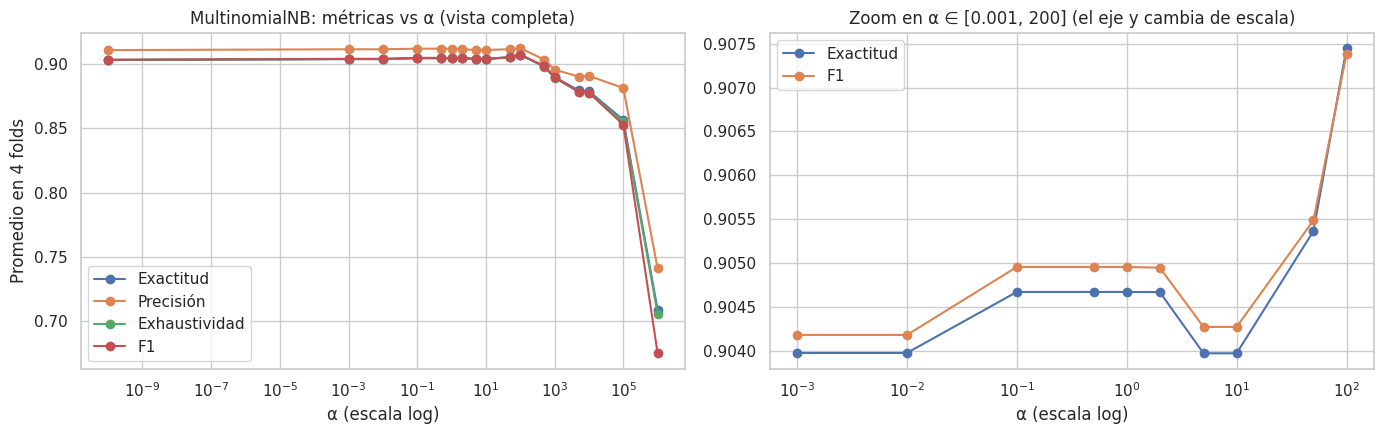

In [9]:
alphas = [1e-10, 1e-3, 1e-2, 0.1, 0.5, 1, 2, 5, 10, 50, 100, 500, 1000, 5000, 1e4, 1e5, 1e6]

res = []
for a in alphas:
    m = cv_metrics(MultinomialNB(alpha=a, force_alpha=True))
    res.append({"alpha": a, **m})
res = pd.DataFrame(res)

mostrar = res.rename(columns={"accuracy": "Exactitud", "precision": "Precisión",
                              "recall": "Exhaustividad", "f1": "F1", "accuracy_std": "Desv. exactitud"})
display(mostrar.round(4).style.format({"alpha": "{:g}"}).hide(axis="index"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(alphas))
for col, nombre in [("accuracy", "Exactitud"), ("precision", "Precisión"), ("recall", "Exhaustividad"), ("f1", "F1")]:
    ax[0].plot(res["alpha"], res[col], marker="o", label=nombre)
ax[0].set_xscale("log"); ax[0].set_xlabel("α (escala log)"); ax[0].set_ylabel("Promedio en 4 folds")
ax[0].set_title("MultinomialNB: métricas vs α (vista completa)"); ax[0].legend()

zoom = res[res["alpha"].between(1e-3, 200)]
for col, nombre in [("accuracy", "Exactitud"), ("f1", "F1")]:
    ax[1].plot(zoom["alpha"], zoom[col], marker="o", label=nombre)
ax[1].set_xscale("log"); ax[1].set_xlabel("α (escala log)")
ax[1].set_title("Zoom en α ∈ [0.001, 200] (el eje y cambia de escala)"); ax[1].legend()
plt.tight_layout(); plt.show()

### 8.3. ¿Por qué α se comporta así? (a partir de la fórmula de Laplace)

$$\theta_{cj}=\frac{N_{cj}+\alpha}{N_c+64\,\alpha}$$

* **α ≈ 0:** sin suavizado; $\theta_{cj}$ es la frecuencia relativa observada (estimación de máxima verosimilitud). Puede ser cero, con los problemas descritos arriba. Es el régimen de **mayor varianza**.
* **α pequeño (≈ 0.1–1):** solo "rellena" los ceros con una probabilidad minúscula. Los $N_{cj}$ de los píxeles con tinta son grandes (cientos o miles de unidades por clase), así que casi no se alteran. El desempeño es prácticamente **plano** en esta zona.
* **α muy grande (≫ 1000, p. ej. ≥ 10⁵):** $\alpha$ domina sobre los conteos, $\theta_{cj}\to 1/64$ para todos los píxeles, y las 10 clases se vuelven indistinguibles (distribución uniforme). Esto es **sobreajuste a la inversa (subajuste, alto sesgo)**: el modelo ignora los datos y las métricas caen. Las tres métricas (exactitud, precisión, exhaustividad, F1) caen juntas porque las clases están balanceadas.

Es decir, α controla el compromiso **sesgo–varianza**: valores bajos → poco sesgo pero riesgo por ceros; valores muy altos → mucho sesgo. La ilustración siguiente (tomada del ejemplo $p_1=1/10,\,p_2=2/10,\,p_3=7/10$ de las diapositivas) muestra cómo α "aplana" una distribución:

,k = 0,k = 0.1,k = 1,k = 100
p1,0.1,0.1068,0.1538,0.3258
p2,0.2,0.2039,0.2308,0.3290
p3,0.7,0.6893,0.6154,0.3452
suma,1.0,1.0000,1.0000,1.0000


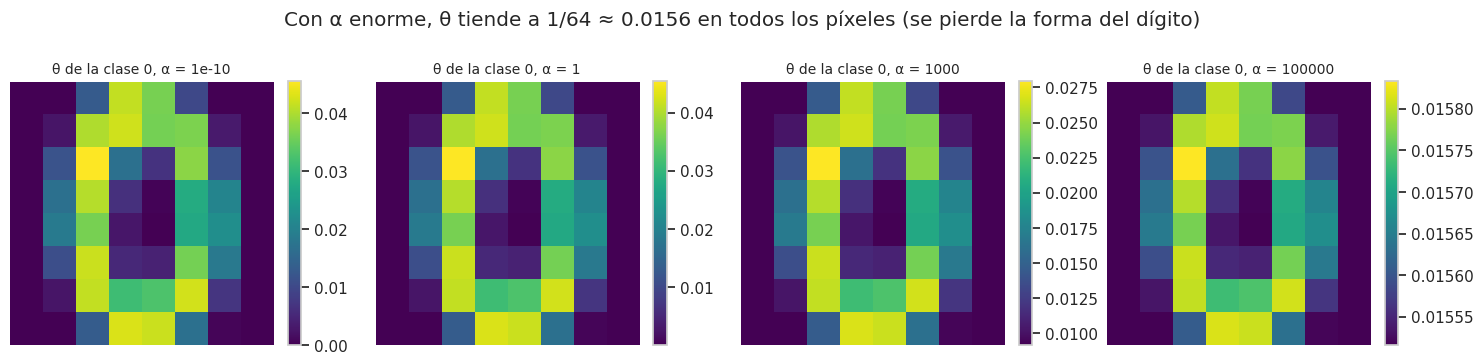

In [10]:
conteos = np.array([1, 2, 7])
tabla_laplace = {}
for k in [0, 0.1, 1, 100]:
    p = (conteos + k) / (conteos.sum() + len(conteos) * k)
    tabla_laplace[f"k = {k}"] = np.append(p, p.sum())
display(pd.DataFrame(tabla_laplace, index=["p1", "p2", "p3", "suma"]).round(4))

# Mismo efecto en un modelo real: distribución de probabilidades de la clase 0 sobre los 64 píxeles
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a_, a in zip(ax, [1e-10, 1, 1000, 1e5]):
    th = MultinomialNBManual(alpha=a).fit(X_train, y_train).theta_[0].reshape(8, 8)
    im = a_.imshow(th, cmap="viridis"); a_.set_title(f"θ de la clase 0, α = {a:g}", fontsize=10); a_.axis("off")
    plt.colorbar(im, ax=a_, fraction=0.046)
plt.suptitle("Con α enorme, θ tiende a 1/64 ≈ 0.0156 en todos los píxeles (se pierde la forma del dígito)", y=1.04)
plt.tight_layout(); plt.show()

### 8.4. Comparación con `CategoricalNB`
`CategoricalNB` estima, para cada píxel y cada clase, una probabilidad sobre **17 categorías**: sus denominadores son pequeños (~140 imágenes por clase) y muchas celdas quedan vacías, por lo que α sí le afecta de forma mucho más marcada. Es una buena ilustración de la regla "el efecto de α depende de cuántos datos respaldan cada probabilidad".

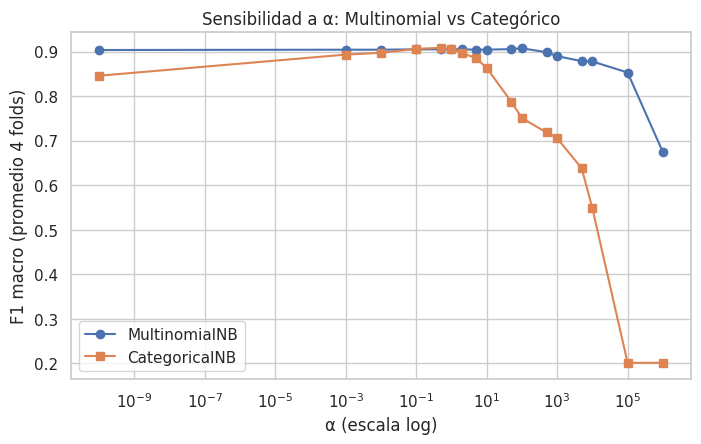

In [11]:
res_cat = []
for a in alphas:
    m = cv_metrics(CategoricalNB(alpha=a, force_alpha=True, min_categories=17))
    res_cat.append({"alpha": a, **m})
res_cat = pd.DataFrame(res_cat)

plt.figure(figsize=(8, 4.5))
plt.plot(res["alpha"], res["f1"], marker="o", label="MultinomialNB")
plt.plot(res_cat["alpha"], res_cat["f1"], marker="s", label="CategoricalNB")
plt.xscale("log"); plt.xlabel("α (escala log)"); plt.ylabel("F1 macro (promedio 4 folds)")
plt.title("Sensibilidad a α: Multinomial vs Categórico"); plt.legend(); plt.show()

## 9. Selección de α y evaluación final en el conjunto de prueba

Se elige α con `GridSearchCV` (K = 4, métrica F1 macro) **solo con los datos de entrenamiento**. Luego se reentrena con todo el 80 % y se evalúa una única vez en el 20 % de prueba.

In [12]:
grid = GridSearchCV(MultinomialNB(force_alpha=True),
                    param_grid={"alpha": [1e-10, 1e-3, 1e-2, 0.1, 0.5, 1, 2, 5, 10, 50, 100, 500, 1000]},
                    scoring="f1_macro", cv=cv, refit=True)
grid.fit(X_train, y_train)

print("Mejor α (según CV):", grid.best_params_["alpha"])
print("F1 macro en CV con ese α: %.4f" % grid.best_score_)

# Valores de α cercanos al óptimo: ¿la diferencia es relevante?
cvr = pd.DataFrame(grid.cv_results_)[["param_alpha", "mean_test_score", "std_test_score"]]
display(cvr.sort_values("mean_test_score", ascending=False).head(6).round(4))

Mejor α (según CV): 100
F1 macro en CV con ese α: 0.9074


,param_alpha,mean_test_score,std_test_score
10,100.0,0.9074,0.0085
9,50.0,0.9055,0.0098
5,1.0,0.9050,0.0117
3,0.1,0.9050,0.0117
4,0.5,0.9050,0.0117
6,2.0,0.9049,0.0111


=== Desempeño en el conjunto de PRUEBA (20 %) ===
Exactitud:                 0.8833
Precisión (macro):         0.8814
Exhaustividad (macro):     0.8830
F1 (macro):                0.8809

              precision    recall  f1-score   support

           0      0.972     0.972     0.972        36
           1      0.719     0.639     0.676        36
           2      0.842     0.914     0.877        35
           3      0.973     0.973     0.973        37
           4      0.923     1.000     0.960        36
           5      0.969     0.838     0.899        37
           6      0.944     0.944     0.944        36
           7      0.900     1.000     0.947        36
           8      0.794     0.771     0.783        35
           9      0.778     0.778     0.778        36

    accuracy                          0.883       360
   macro avg      0.881     0.883     0.881       360
weighted avg      0.882     0.883     0.882       360



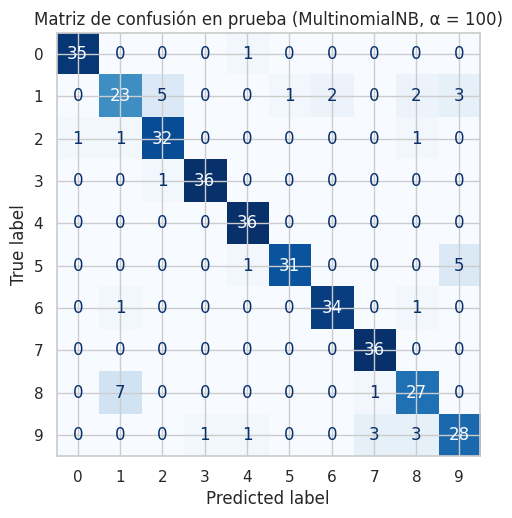

In [13]:
modelo_final = grid.best_estimator_
y_pred = modelo_final.predict(X_test)

print("=== Desempeño en el conjunto de PRUEBA (20 %) ===")
print(f"Exactitud:                 {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisión (macro):         {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Exhaustividad (macro):     {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1 (macro):                {f1_score(y_test, y_pred, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión en prueba (MultinomialNB, α = {grid.best_params_['alpha']:g})")
plt.show()

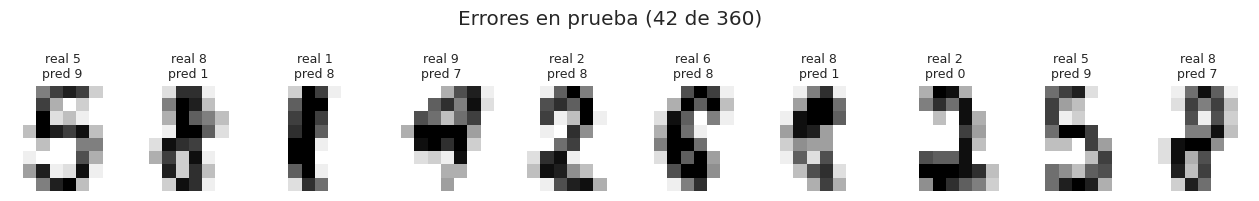

In [14]:
# Ejemplos mal clasificados
err = np.where(y_pred != y_test)[0]
n = min(10, len(err))
fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.2))
for a_, i in zip(np.atleast_1d(axes), err[:n]):
    a_.imshow(X_test[i].reshape(8, 8), cmap="gray_r"); a_.axis("off")
    a_.set_title(f"real {y_test[i]}\npred {y_pred[i]}", fontsize=9)
plt.suptitle(f"Errores en prueba ({len(err)} de {len(y_test)})", y=1.08); plt.show()

## 10. Conclusiones

1. **Partición y validación:** 80 % / 20 % estratificado y K-fold = 4 (estratificado) sobre el entrenamiento; el conjunto de prueba solo se usó al final.
2. **Mejor clasificador:** `MultinomialNB`. Los píxeles de `digits` son **intensidades enteras no negativas (0–16)** con un gran pico en 0, sin forma de campana (la prueba de normalidad rechaza la hipótesis Gaussiana en casi todos los casos). Por eso el modelo Multinomial (conteos discretos) se ajusta mejor que el Gaussiano o el Bernoulli (que pierde la intensidad), y el Complementario no aporta porque las clases están balanceadas. `CategoricalNB` empata en exactitud, pero es menos parsimonioso, ignora el orden de las intensidades y es mucho más sensible a α.
3. **Suavizado de Laplace:** su función principal es **evitar probabilidades cero** (que anulan una clase completa). En `digits` con `MultinomialNB` el efecto de α es **pequeño en el rango ≈ 0.001–100** (los conteos por clase son grandes, α los altera poco; las diferencias están dentro de la desviación entre folds) y **perjudicial para α muy grande**: la caída empieza hacia α ≈ 1000 y se vuelve drástica para α ≥ 10⁵, donde las probabilidades tienden a la uniforme 1/64 y exactitud, precisión, exhaustividad y F1 caen juntas. El α que `GridSearchCV` elige (100) supera a α = 1 por una diferencia mínima, menor que la desviación entre folds; no es una mejora estadísticamente significativa. Con α = 0 estricto el modelo falla en imágenes con tinta en píxeles nunca vistos para la clase correcta. Un α pequeño (p. ej. 1, el valor clásico de Laplace) es una elección segura.
4. **Limitaciones:** el supuesto de independencia entre píxeles es fuerte (los píxeles vecinos están correlacionados), lo que limita Naïve Bayes a ≈ 88–90 % de exactitud en este problema; modelos que capturan esa estructura (SVM, redes neuronales, k-NN) llegan a más de 97 %.